# 05 · Comparing annual pair-count models: Poisson log-linear models

**Question.** How much better do changing reference expectations and a constant pair structure fit the annual pair counts than a model with constant pair shares?

**Models** for the observed count $O_{ht}$ of pair $h$ in year $t$, with the reference expectation $E_{ht}$ (notebook 02) as offset. They are fitted on the primary eligible pairs; years are layers, as in the comparison of mobility tables.

| Model | $\log\mu_{ht}$ | Reading |
|---|---|---|
| M0 | $\log E_{ht}+c_t$ | tactics combine at random given frequencies and list sizes |
| M1 | $\log E_{ht}+c_t+\psi_h$ | one combination structure for all years |
| M2 | $\log E_{ht}+c_t+\varphi_t\psi_h$ | same pattern, year-specific strength $\varphi_t$ (uniform difference; Xie 1992) |
| MA | $c_t+\gamma_h$ | constant pair shares: no use of the reference at all |
| saturated | $\log O_{ht}$ | year-specific structure |

M1 and MA have the same number of parameters. M1 incorporates year-specific reference expectations and a common association for each pair. Under N2 these expectations reflect territory, conflict field and coding position, as well as marginal frequencies and list length. The raw contrast is the relative reduction in residual deviance, $1-D(\mathrm{M1})/D(\mathrm{MA})$. A second contrast uses Pearson statistics after subtracting the estimated within-year dispersion floor from both models. A separate permutation-floor contrast is reported when its denominator permits interpretation.

Column names beginning with `frequency_share_` are retained for compatibility with the archived numerical results. They refer to relative model-fit improvements. The models do not estimate a causal contribution of frequency change.

$\varphi_t$ is normalised to a geometric mean of 1 over years and $\psi$ is centred (weighted by expected counts), so $\varphi_t>1$ means tactics are bundled and avoided more sharply than in a typical year. Intervals: day-block bootstrap within years (999 draws, seed 20261106). Fits are checked with independent implementations (statsmodels GLM for M1; direct numerical maximisation for M2).

**Addendum 2 (written after notebooks 03–04, reported as post-results).** Two calibration tools of notebook 04 turned out to be biased: the bootstrap intervals for correlations are attenuated, and the pseudo-count $I^2$ is distorted by zero counts. This notebook therefore adds a likelihood-based check calibrated within each year. Each year's Pearson $X^2$ against the constant structure estimated from the other years is compared with the $X^2$ between two random halves of the same year (protest days kept whole). The result is a quasi-Poisson $F$ ratio. The same within-year dispersion provides a second noise floor for the decomposition and the denominator of the test for uniform strength change.

The saved output of the original model run is retained here. Running the cells recomputes the estimates and displays the generated tables before writing them.

In [1]:
import os
for k in ["OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS"]:
    os.environ.setdefault(k, "2")
import json, itertools, time
from pathlib import Path
from IPython.display import display
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import minimize
import statsmodels.api as sm

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
CFG = json.loads((ROOT / "config" / "analysis_config_v2.json").read_text())
TAB = ROOT / "results" / "tables"; AGG = ROOT / "results" / "aggregates"; LOCAL = ROOT / "data_local"
FROM_AGG = os.environ.get("PROTEST_FROM_AGGREGATES") == "1"
def display_and_export_table(df, name, index=False, float_format="%.4f"):
    display(df)
    df.to_csv(TAB / f"{name}.csv", index=index)
    df.to_latex(TAB / f"{name}.tex", index=index, escape=True, float_format=lambda x: float_format % x)
    return df
PAIRS = np.array(list(itertools.combinations(range(1, 36), 2)))
YEARS = np.arange(2008, 2025); T = len(YEARS)
elig = np.load(AGG / "eligible_primary.npy"); H = np.where(elig)[0]
REFS = ["N2", "N1", "N2_clean"]
perms = np.load(AGG / "permutations_calendar_month.npy").astype(int)
print("pairs in models:", len(H), "| cells:", len(H) * T, "| permutations:", len(perms))

pairs in models: 291 | cells: 4947 | permutations: 999


## 1. Fitting routines

In [2]:
def deviance(O, mu):
    with np.errstate(divide="ignore", invalid="ignore"):
        t = np.where(O > 0, O * np.log(O / mu), 0.0)
    return float(2 * np.sum(t - (O - mu)))

def fit_M0(O, E):
    c = O.sum(1, keepdims=True) / E.sum(1, keepdims=True)
    return E * c

def fit_M1(O, E, tol=1e-10, max_iter=5000):
    """Iterative proportional fitting of mu = E * a_t * b_h to the year and pair margins of O."""
    a = np.ones((O.shape[0], 1)); b = np.ones((1, O.shape[1]))
    for it in range(max_iter):
        nb_, db_ = O.sum(0, keepdims=True), (E * a).sum(0, keepdims=True)
        b_new = np.divide(nb_, db_, out=np.zeros_like(nb_, dtype=float), where=db_ > 0)   # pairs with E = 0 everywhere stay at 0
        na_, da_ = O.sum(1, keepdims=True), (E * b_new).sum(1, keepdims=True)
        a_new = np.divide(na_, da_, out=np.ones_like(na_, dtype=float), where=da_ > 0)
        done = np.nanmax(np.abs(a_new - a)) < tol and np.nanmax(np.abs(b_new - b)) < tol
        a, b = a_new, b_new
        if done:
            break
    return E * a * b, a.ravel(), b.ravel()

def fit_MA(O):
    return O.sum(1, keepdims=True) * O.sum(0, keepdims=True) / O.sum()

def fit_M2(O, E, max_iter=500, tol=1e-9):
    """Uniform-difference model mu = E exp(c_t + phi_t psi_h) by alternating Newton steps.
    Pairs never observed in any year have mu = 0 (psi = -inf) and carry no information on phi."""
    live = O.sum(0) > 0
    Ol, El = O[:, live], E[:, live]
    mu1, a, b = fit_M1(Ol, El)
    w = El.sum(0)
    psi = np.log(b); psi -= np.average(psi, weights=w)
    phi = np.ones(O.shape[0]); c = np.log(Ol.sum(1) / (El * np.exp(phi[:, None] * psi[None, :])).sum(1))
    ll_old = -np.inf
    for it in range(max_iter):
        mu = El * np.exp(c[:, None] + phi[:, None] * psi[None, :])
        g = (phi[:, None] * (Ol - mu)).sum(0); hss = (phi[:, None] ** 2 * mu).sum(0)
        psi = psi + np.clip(g / hss, -1, 1)
        mu = El * np.exp(c[:, None] + phi[:, None] * psi[None, :])
        g = (psi[None, :] * (Ol - mu)).sum(1); hss = (psi[None, :] ** 2 * mu).sum(1)
        phi = phi + np.clip(g / hss, -.5, .5)
        shift = np.average(psi, weights=w); psi -= shift; c = c + phi * shift
        gm = np.exp(np.mean(np.log(np.abs(phi)))); phi /= gm; psi *= gm
        c = np.log(Ol.sum(1) / (El * np.exp(phi[:, None] * psi[None, :])).sum(1))
        mu = El * np.exp(c[:, None] + phi[:, None] * psi[None, :])
        ll = float(np.sum(np.where(Ol > 0, Ol * np.log(mu), 0) - mu))
        if abs(ll - ll_old) < tol * (1 + abs(ll)):
            break
        ll_old = ll
    full = np.zeros_like(O, dtype=float); full[:, live] = mu
    psi_full = np.full(O.shape[1], -np.inf); psi_full[live] = psi
    return full, phi, psi_full, c, it

def all_deviances(O, E):
    return {"D_M0": deviance(O, fit_M0(O, E)), "D_M1": deviance(O, fit_M1(O, E)[0]),
            "D_M2": deviance(O, fit_M2(O, E)[0]), "D_MA": deviance(O, fit_MA(O))}

## 2. Independent checks of the fits (primary reference)

In [3]:
z = np.load(AGG / "null_N2.npz")
O = z["observed_year"][:, H].astype(float); E = z["counts"].mean(0)[:, H]
live = O.sum(0) > 0
# M1 by IPF versus a Poisson GLM with year and pair dummies and log E as offset
mu_ipf = fit_M1(O[:, live], E[:, live])[0]
rows_t, cols_h = np.meshgrid(np.arange(T), np.arange(live.sum()), indexing="ij")
pos = E[:, live] > 0                       # cells with E = 0 have O = 0 and carry no information
assert np.all(O[:, live][~pos] == 0)
X = pd.get_dummies(pd.DataFrame({"t": rows_t[pos].astype(str), "h": cols_h[pos].astype(str)}), drop_first=True).astype(float)
X.insert(0, "const", 1.0)
glm = sm.GLM(O[:, live][pos], X.to_numpy(), family=sm.families.Poisson(), offset=np.log(E[:, live][pos])).fit(tol=1e-12, maxiter=200)
check_m1 = {"cells_E_zero": int((~pos).sum()), "D_M1_ipf": deviance(O[:, live], mu_ipf), "D_M1_glm": float(glm.deviance),
            "max_abs_fitted_diff": float(np.max(np.abs(glm.fittedvalues - mu_ipf[pos])))}
# M2 by alternating Newton versus direct L-BFGS maximisation of the Poisson likelihood
mu2, phi2, psi2, c2, iters = fit_M2(O, E)
Ol, El = O[:, live], E[:, live]; nH = Ol.shape[1]
logE = np.where(El > 0, np.log(np.where(El > 0, El, 1)), -np.inf)
def nll(par):
    c = par[:T]; lphi = par[T:2 * T]; psi = par[2 * T:]
    lin = c[:, None] + np.exp(lphi)[:, None] * psi[None, :]
    mu = np.where(El > 0, El * np.exp(lin), 0.0)
    f = np.sum(mu - np.where(El > 0, Ol * (logE + lin), 0.0))
    r = Ol - mu
    gc = -r.sum(1); gl = -(r * psi[None, :]).sum(1) * np.exp(lphi); gp = -(r * np.exp(lphi)[:, None]).sum(0)
    return f, np.concatenate([gc, gl, gp])
x0 = np.concatenate([np.zeros(T), np.zeros(T), np.log(np.maximum(Ol.sum(0), .5) / El.sum(0))])
opt = minimize(nll, x0, jac=True, method="L-BFGS-B", options={"maxiter": 20000, "maxfun": 40000, "ftol": 1e-15, "gtol": 1e-9})
cc, lphi, pp = opt.x[:T], opt.x[T:2 * T], opt.x[2 * T:]
phi_direct = np.exp(lphi); g = np.exp(np.mean(np.log(phi_direct)))
mu_direct = El * np.exp(cc[:, None] + phi_direct[:, None] * pp[None, :])
check_m2 = {"iterations_alternating": iters, "D_M2_alternating": deviance(O, mu2), "D_M2_direct": deviance(Ol, mu_direct),
            "max_abs_phi_diff": float(np.max(np.abs(phi_direct / g - phi2))), "lbfgs_converged": bool(opt.success)}
checks = {**check_m1, **check_m2}
display(checks)
(ROOT / "results" / "05_fit_checks.json").write_text(json.dumps(checks, indent=1) + "\n");

<cell 2>:48: RuntimeWarning: divide by zero encountered in log
<cell 2>:48: RuntimeWarning: invalid value encountered in multiply
<cell 3>:22: RuntimeWarning: invalid value encountered in multiply


{'cells_E_zero': 338, 'D_M1_ipf': 4349.815356721944, 'D_M1_glm': 4349.815356721944, 'max_abs_fitted_diff': 1.871569565992104e-10, 'iterations_alternating': 9, 'D_M2_alternating': 4302.826010069264, 'D_M2_direct': 4302.825961546239, 'max_abs_phi_diff': 0.00019907091379378627, 'lbfgs_converged': True}


## 2b. Per-year departure from the common structure, calibrated within the year (addendum 2)

For year $t$: $\mu_{ht}=E_{ht}\,a_t\,b_h^{(-t)}$, where $b^{(-t)}$ is the M1 pair effect estimated from the other 16 years and $a_t$ matches year $t$'s total. $X^2_{\text{between}}$ is computed over cells with $E_{ht}\ge2$ (df = cells − 1). For the same cells, year $t$'s days are split at random into halves (50 splits). A common within-year structure is fitted to the 2 × cells table, and its Pearson $X^2$ per df gives the year's noise dispersion, which includes the clustering of actions on the same day. $F_t$ is the ratio of the two. $F_t\approx1$ means year $t$ departs from the other years no more than its two halves depart from each other. $1-1/F_t$ is the share of the departure beyond noise. Pairs never observed in the other years cannot be scored against them; they are counted and set aside.

In [4]:

from scipy.stats import f as f_dist
SPLIT_SEED, NSPLIT, MIN_E = 20261108, 50, 2.0
def pearson(O, mu):
    m = mu > 0
    return float(((O[m] - mu[m]) ** 2 / mu[m]).sum())

def load_days(name):
    z = np.load(LOCAL / f"day_OE_{name}.npz", allow_pickle=True)
    days = pd.to_datetime(z["days"]); return z["observed"][:, H].astype(float), z["expected"][:, H].astype(float), days.year.to_numpy() - 2008

F_rows = []
if not FROM_AGG:
    for name in REFS:
        z = np.load(AGG / f"null_{name}.npz")
        O = z["observed_year"][:, H].astype(float); E = z["counts"].mean(0)[:, H]
        Od, Ed, yidx = load_days(name)
        rng_s = np.random.default_rng(SPLIT_SEED)
        for ti, yr in enumerate(YEARS):
            others = [s for s in range(T) if s != ti]
            _, _, b_o = fit_M1(O[others], E[others])
            cells = (E[ti] >= MIN_E) & (b_o > 0)
            new_pairs = int(((E[ti] >= MIN_E) & (b_o == 0) & (O[ti] > 0)).sum())
            mu_b = E[ti, cells] * b_o[cells]; mu_b *= O[ti, cells].sum() / mu_b.sum()
            X2_b = pearson(O[ti, cells], mu_b); df_b = int(cells.sum() - 1)
            days = np.where(yidx == ti)[0]; X2w, dfw = [], []
            for s in range(NSPLIT):
                perm = rng_s.permutation(len(days)); h1, h2 = days[perm[: len(days) // 2]], days[perm[len(days) // 2:]]
                O2 = np.stack([Od[h1][:, cells].sum(0), Od[h2][:, cells].sum(0)]); E2 = np.stack([Ed[h1][:, cells].sum(0), Ed[h2][:, cells].sum(0)])
                pos = O2.sum(0) > 0
                mu2 = fit_M1(O2[:, pos], E2[:, pos])[0]
                X2w.append(pearson(O2[:, pos], mu2)); dfw.append(int(pos.sum() - 1))
            disp = np.mean(X2w) / np.mean(dfw)
            Ft = (X2_b / df_b) / disp
            F_rows.append({"reference": name, "year": yr, "cells": int(cells.sum()), "pairs_new_vs_other_years": new_pairs,
                           "X2_between": X2_b, "df_between": df_b, "X2_within_mean": np.mean(X2w), "df_within_mean": np.mean(dfw),
                           "dispersion_within": disp, "F": Ft, "p_F": f_dist.sf(Ft, df_b, np.mean(dfw)),
                           "share_beyond_noise": max(0.0, 1 - 1 / Ft)})
        print(name, "per-year F done", flush=True)
    Ftab = pd.DataFrame(F_rows)
    Ftab["p_holm"] = np.nan
    for name, g in Ftab.groupby("reference"):
        order = g.p_F.sort_values().index; m = len(order)
        adj = np.maximum.accumulate([min(1, (m - k) * Ftab.loc[i, "p_F"]) for k, i in enumerate(order)])
        Ftab.loc[order, "p_holm"] = adj
    display_and_export_table(Ftab, "annual_departure_F")
    glob_rows = []
    for name, g in Ftab.groupby("reference", sort=False):
        Fg = (g.X2_between.sum() / g.df_between.sum()) / (g.X2_within_mean.sum() / g.df_within_mean.sum())
        glob_rows.append({"reference": name, "F_pooled": Fg, "share_beyond_noise_pooled": max(0, 1 - 1 / Fg),
                          "pooled_dispersion_within": g.X2_within_mean.sum() / g.df_within_mean.sum(),
                          "p_F_pooled": f_dist.sf(Fg, g.df_between.sum(), g.df_within_mean.sum()),
                          "years_p_holm_lt_05": int((g.p_holm < .05).sum()),
                          "years_list": ",".join(str(v) for v in g.loc[g.p_holm < .05, "year"])})
    Fglob = display_and_export_table(pd.DataFrame(glob_rows), "departure_F_pooled")
else:
    Ftab = pd.read_csv(TAB / "annual_departure_F.csv"); Fglob = pd.read_csv(TAB / "departure_F_pooled.csv")
display(Fglob.round(3))
Ftab[Ftab.reference == "N2"].round(3)

N2 per-year F done
N1 per-year F done
N2_clean per-year F done


,reference,F_pooled,share_beyond_noise_pooled,pooled_dispersion_within,p_F_pooled,years_p_holm_lt_05,years_list
0,N2,1.842,0.457,1.298,0.0,4,"2016,2019,2020,2021"
1,N1,2.487,0.598,1.353,0.0,9,"2011,2013,2015,2016,2018,2019,2020,2021,2022"
2,N2_clean,1.501,0.334,1.284,0.0,2,"2020,2021"


,reference,year,cells,pairs_new_vs_other_years,X2_between,df_between,X2_within_mean,df_within_mean,dispersion_within,F,p_F,share_beyond_noise,p_holm
0,N2,2008,99,2,179.734,98,127.409,88.0,1.448,1.267,0.130,0.211,1.000
1,N2,2009,94,0,130.835,93,100.353,85.0,1.181,1.192,0.206,0.161,1.000
2,N2,2010,72,0,64.284,71,66.779,60.0,1.113,0.813,0.799,0.000,1.000
3,N2,2011,139,0,197.555,138,138.978,121.0,1.149,1.246,0.108,0.198,0.968
4,N2,2012,111,1,209.211,110,106.396,94.0,1.132,1.680,0.005,0.405,0.066
5,N2,2013,118,0,155.774,117,121.950,103.0,1.184,1.125,0.272,0.111,1.000
6,N2,2014,101,0,149.414,100,107.729,86.0,1.253,1.193,0.201,0.162,1.000
7,N2,2015,77,0,125.242,76,77.554,67.0,1.158,1.424,0.071,0.298,0.777
8,N2,2016,117,1,267.920,116,134.123,101.0,1.328,1.739,0.002,0.425,0.033
9,N2,2017,84,0,93.386,83,91.908,74.0,1.242,0.906,0.670,0.000,1.000


## 3. Deviance decomposition with noise floors

Two noise floors are reported. The frozen one is the mean deviance over calendar-month permutations. As anticipated in addendum 1, pseudo-years are not size-matched to real years: they have more uniform sizes and fewer cells with tiny expected counts, so their deviance is inflated. If that floor exceeds the observed deviance, it cannot be used, and the result is reported as such. The addendum-2 floor uses the within-year dispersion (Pearson $X^2$ between random halves of each year) times the residual degrees of freedom. The raw comparison reports the reduction in residual deviance; the dispersion-adjusted comparison uses Pearson statistics. The two values are separate measures of fit.

In [5]:
T0 = time.time()
dec_rows = []; perm_store = {}
for name in REFS:
    z = np.load(AGG / f"null_{name}.npz")
    O = z["observed_year"][:, H].astype(float); E = z["counts"].mean(0)[:, H]
    obs = all_deviances(O, E)
    zm = np.load(AGG / f"month_OE_{name}.npz", allow_pickle=True)
    Om = zm["observed"][:, H].astype(float).reshape(T, 12, len(H)); Em = zm["expected"][:, H].astype(float).reshape(T, 12, len(H))
    assert np.allclose(Om.sum(1), O) and np.allclose(Em.sum(1), E, rtol=1e-4, atol=1e-3)
    pd_rows = []
    for b in range(len(perms)):
        Op = np.zeros_like(O); Ep = np.zeros_like(E)
        for mo in range(12):
            Op[perms[b, mo]] += Om[:, mo]; Ep[perms[b, mo]] += Em[:, mo]
        pd_rows.append(all_deviances(Op, Ep))
    pdv = pd.DataFrame(pd_rows); perm_store[name] = pdv
    display(pdv)
    pdv.to_csv(TAB / f"permutation_deviances_{name}.csv", index=False)
    finite = pdv.replace([np.inf, -np.inf], np.nan)
    floor = finite.mean()                       # a few pseudo-years can contain an observed pair whose Monte Carlo expectation is 0 there
    ex_M1 = obs["D_M1"] - floor["D_M1"]; ex_MA = obs["D_MA"] - floor["D_MA"]
    dec_rows.append({"reference": name, "pairs_with_expected": int((E.sum(0) > 0).sum()), "cells": O.size, **obs,
                     "perm_mean_D_M1": floor["D_M1"], "perm_mean_D_MA": floor["D_MA"], "perm_mean_D_M2": floor["D_M2"],
                     "share_structure_constant": 1 - obs["D_M1"] / obs["D_M0"],
                     "share_change_uniform_strength": (obs["D_M1"] - obs["D_M2"]) / obs["D_M1"],
                     "frequency_share_raw": 1 - obs["D_M1"] / obs["D_MA"],
                     "frequency_share_permutation_floor": 1 - ex_M1 / ex_MA,
                     "excess_D_M1_over_noise": ex_M1, "excess_D_MA_over_noise": ex_MA,
                     "permutations_infinite_deviance": int(np.isinf(pdv.D_M1).sum()),
                     "p_perm_D_M1": (1 + (pdv.D_M1 >= obs["D_M1"]).sum()) / (len(pdv) + 1),
                     "p_perm_uniform_term": (1 + ((pdv.D_M1 - pdv.D_M2) >= (obs["D_M1"] - obs["D_M2"])).sum()) / (len(pdv) + 1)})
    print(name, "done", round(time.time() - T0, 1), "s", flush=True)
dec = pd.DataFrame(dec_rows)
# addendum 2: dispersion-based noise floor (Pearson X2) and quasi-likelihood F for uniform strength change
disp_pooled = Fglob.set_index("reference")["pooled_dispersion_within"]
extra = []
for name in REFS:
    z = np.load(AGG / f"null_{name}.npz")
    O = z["observed_year"][:, H].astype(float); E = z["counts"].mean(0)[:, H]
    live = O.sum(0) > 0; O, E = O[:, live], E[:, live]
    mu1 = fit_M1(O, E)[0]; muA = fit_MA(O); mu2 = fit_M2(O, E)[0]
    df_res = (T - 1) * (O.shape[1] - 1); phi_hat = disp_pooled[name]
    X1, XA = pearson(O, mu1), pearson(O, muA)
    D1, D2 = deviance(O, mu1), deviance(O, mu2)
    Fu = ((D1 - D2) / (T - 1)) / phi_hat
    extra.append({"reference": name, "X2_M1": X1, "X2_MA": XA, "df_residual_M1": df_res, "pooled_dispersion_within": phi_hat,
                  "frequency_share_dispersion_floor": 1 - (X1 - phi_hat * df_res) / (XA - phi_hat * df_res),
                  "F_uniform_strength": Fu, "p_F_uniform_strength": f_dist.sf(Fu, T - 1, df_res)})
dec = display_and_export_table(dec.merge(pd.DataFrame(extra), on="reference"), "loglinear_decomposition")
dec.round(4).T

N2 done 2.9 s
N1 done 6.5 s
N2_clean done 10.3 s


<cell 2>:48: RuntimeWarning: divide by zero encountered in log
<cell 2>:48: RuntimeWarning: invalid value encountered in multiply


,0,1,2
reference,N2,N1,N2_clean
pairs_with_expected,291,291,230
cells,4947,4947,4947
D_M0,14025.0639,24067.803,8805.7016
D_M1,4349.8154,5813.8771,2804.6482
D_M2,4302.826,5510.7829,2772.2055
D_MA,15126.5436,15126.5436,8136.9398
perm_mean_D_M1,5476.9374,4852.5474,3549.614
perm_mean_D_MA,8448.4337,8448.4337,5182.3281
perm_mean_D_M2,5446.3753,4758.3817,3515.0102


## 4. Year-specific strength of the structure, φ_t, with day-block bootstrap intervals

In [6]:
def load_days(name):
    z = np.load(LOCAL / f"day_OE_{name}.npz", allow_pickle=True)
    days = pd.to_datetime(z["days"]); return z["observed"][:, H].astype(float), z["expected"][:, H].astype(float), days.year.to_numpy() - 2008

B = CFG["loglinear"]["bootstrap"]["B"]
rng = np.random.default_rng(CFG["loglinear"]["bootstrap"]["seed"])
phi_rows = []; contrib_rows = []
for name in REFS:
    z = np.load(AGG / f"null_{name}.npz")
    O = z["observed_year"][:, H].astype(float); E = z["counts"].mean(0)[:, H]
    mu2, phi, psi, c, _ = fit_M2(O, E)
    mu1 = fit_M1(O, E)[0]
    # per-year contribution to D(M1): where does the departure from a constant structure sit?
    with np.errstate(divide="ignore", invalid="ignore"):
        dev_cells = 2 * (np.where(O > 0, O * np.log(O / mu1), 0) - (O - mu1))
    for ti, yr in enumerate(YEARS):
        contrib_rows.append({"reference": name, "year": yr, "D_M1_year": dev_cells[ti].sum(), "cells_E_ge_5": int((E[ti] >= 5).sum()),
                             "share_of_D_M1": dev_cells[ti].sum() / dev_cells.sum()})
    if FROM_AGG:
        boot = None
    else:
        Od, Ed, yidx = load_days(name)
        sets = [np.where(yidx == ti)[0] for ti in range(T)]
        boot = np.zeros((B, T))
        for b in range(B):
            Ob = np.zeros_like(O); Eb = np.zeros_like(E)
            for ti in range(T):
                nd = len(sets[ti]); w = np.bincount(rng.integers(0, nd, nd), minlength=nd).astype(float)
                Ob[ti] = w @ Od[sets[ti]]; Eb[ti] = w @ Ed[sets[ti]]
            boot[b] = fit_M2(Ob, Eb)[1]
        np.save(AGG / f"bootstrap_phi_{name}.npy", boot)
    for ti, yr in enumerate(YEARS):
        phi_rows.append({"reference": name, "year": yr, "phi": phi[ti],
                         "phi_lo": np.quantile(boot[:, ti], .025) if boot is not None else np.nan,
                         "phi_hi": np.quantile(boot[:, ti], .975) if boot is not None else np.nan})
    print(name, "bootstrap done", flush=True)
if FROM_AGG:
    phit = pd.read_csv(TAB / "unidiff_phi_by_year.csv")
else:
    phit = display_and_export_table(pd.DataFrame(phi_rows), "unidiff_phi_by_year")
contrib = display_and_export_table(pd.DataFrame(contrib_rows), "deviance_M1_by_year")
phit[phit.reference == "N2"].round(3)

N2 bootstrap done
N1 bootstrap done
N2_clean bootstrap done


<cell 2>:48: RuntimeWarning: divide by zero encountered in log
<cell 2>:48: RuntimeWarning: invalid value encountered in multiply
<cell 2>:48: RuntimeWarning: divide by zero encountered in log
<cell 2>:48: RuntimeWarning: invalid value encountered in multiply
<cell 2>:48: RuntimeWarning: divide by zero encountered in log
<cell 2>:48: RuntimeWarning: invalid value encountered in multiply
<cell 2>:48: RuntimeWarning: divide by zero encountered in log
<cell 2>:48: RuntimeWarning: invalid value encountered in multiply


,reference,year,phi,phi_lo,phi_hi
0,N2,2008,1.024,0.895,1.192
1,N2,2009,0.987,0.857,1.131
2,N2,2010,1.152,0.989,1.362
3,N2,2011,1.102,1.007,1.206
4,N2,2012,1.093,0.962,1.242
5,N2,2013,1.032,0.919,1.151
6,N2,2014,1.001,0.883,1.120
7,N2,2015,0.921,0.737,1.134
8,N2,2016,0.903,0.752,1.088
9,N2,2017,1.031,0.855,1.236


<cell 2>:48: RuntimeWarning: divide by zero encountered in log
<cell 2>:48: RuntimeWarning: invalid value encountered in multiply


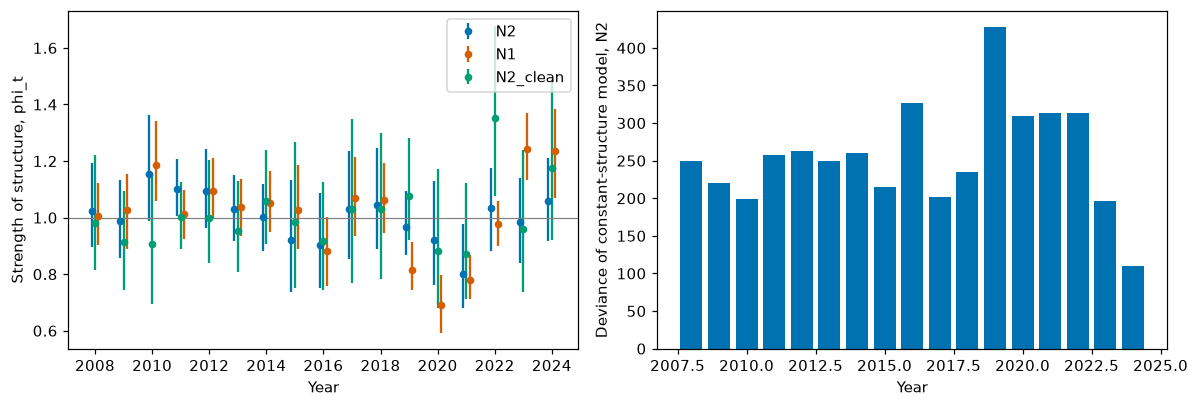

In [7]:
psi_tab = []
for name in REFS:
    z = np.load(AGG / f"null_{name}.npz")
    O = z["observed_year"][:, H].astype(float); E = z["counts"].mean(0)[:, H]
    _, phi, psi, c, _ = fit_M2(O, E)
    psi_tab.append(pd.DataFrame({"reference": name, "code_i": PAIRS[H, 0], "code_j": PAIRS[H, 1], "psi_unidiff": psi,
                                 "log_O_over_E_full_period": np.log((O.sum(0) + .5) / (E.sum(0) + .5))}))
display_and_export_table(pd.concat(psi_tab), "unidiff_psi_by_pair")
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
for name, col, off in [("N2", "#0072B2", -.12), ("N1", "#D55E00", .12), ("N2_clean", "#009E73", 0)]:
    zz = phit[phit.reference == name]
    ax[0].errorbar(zz.year + off, zz.phi, yerr=[zz.phi - zz.phi_lo, zz.phi_hi - zz.phi], fmt="o", ms=4, color=col, label=name)
ax[0].axhline(1, color="0.5", lw=.8); ax[0].set_ylabel("Strength of structure, phi_t"); ax[0].set_xlabel("Year"); ax[0].legend()
zz = contrib[contrib.reference == "N2"]
ax[1].bar(zz.year, zz.D_M1_year, color="#0072B2"); ax[1].set_ylabel("Deviance of constant-structure model, N2"); ax[1].set_xlabel("Year")
fig.tight_layout()
display(fig)
diagnostics = ROOT / "results" / "diagnostics"
diagnostics.mkdir(parents=True, exist_ok=True)
fig.savefig(diagnostics / "05_structure_strength_and_deviance.pdf", bbox_inches="tight")
plt.close(fig)